# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [23]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3 * 1) / 1024**2

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 3600

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = 400 * frames_per_day * frame_mb / 1024**2

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_frame_mb = (640 * 360 * 3) / 1024**2
fleet_tb_small = 400 * (10 * 24 * 3600) * small_frame_mb / 1024**2
pct_pixels_remaining = 100 * (640 * 360) / (1920 * 1080)

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ Downsampling to 640×360 keeps only 11% of the original pixels, so details like faces, licence plates, and logos become blurry when enlarged. This is the loss of spatial information. Reducing 30 fps to 10 fps also misses fast movements between frames, such as a punch or someone starting to run. This is the loss of temporal information. In both cases, the missing details cannot be recovered, and the viewer has to guess what happened.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

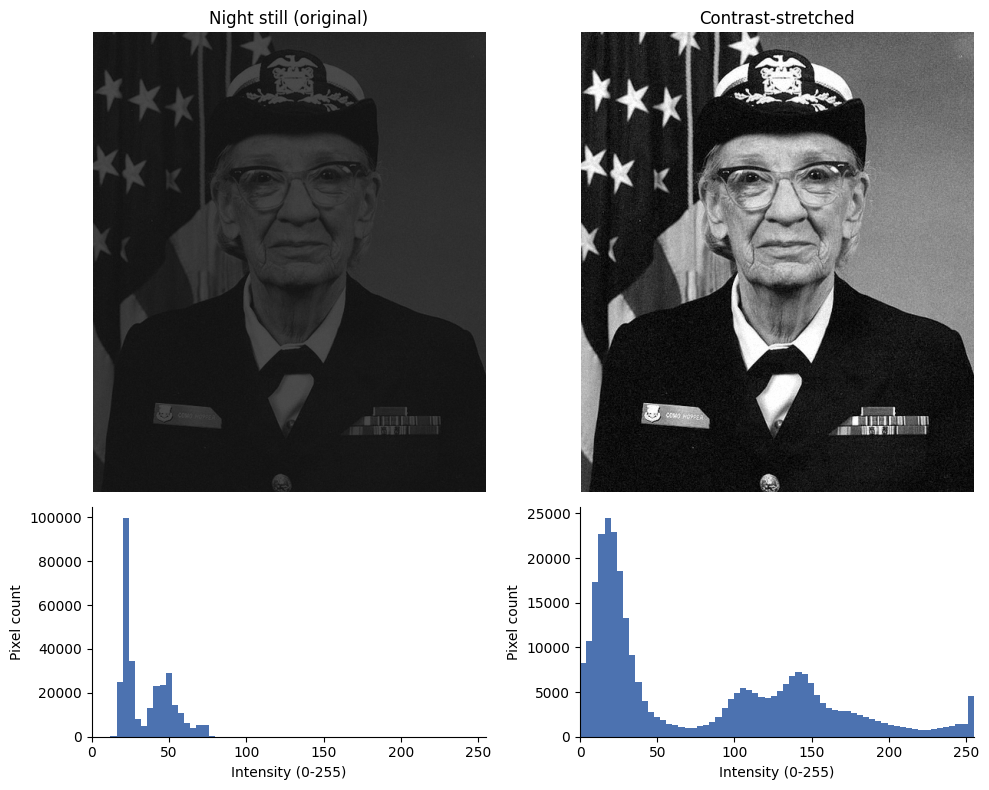

Contrast before: 0.609  ->  after: 1.000


In [24]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

q1, q99 = np.percentile(stretched, [1, 99])
c_after = michelson(q99, q1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for col, (im, title) in enumerate([(night_still, "Night still (original)"),
                                   (stretched, "Contrast-stretched")]):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(title); axes[0, col].axis("off")
    axes[1, col].hist(im.ravel(), bins=64, range=(0, 255), color="#4C72B0")
    axes[1, col].set_xlim(0, 255)
    axes[1, col].set_xlabel("Intensity (0-255)"); axes[1, col].set_ylabel("Pixel count")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The histogram has a narrow peak between 15 and 75, meaning most pixels are dark with very few mid-tones or highlights. This indicates a dark, low-contrast image. Stretching spreads these values across 0 to 255, making details easier to see, but it does not add new information. A histogram also cannot identify objects because it does not show how pixels are arranged. Different images can have the same histogram.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: 68.7 s -> 78.1 s
Running : 78.6 s -> 86.0 s
Audio event: 75.0 s | Lighting event: 100.0 s


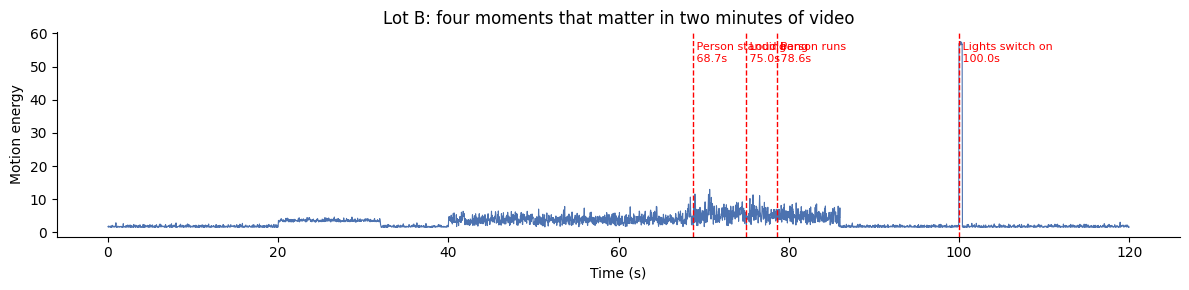

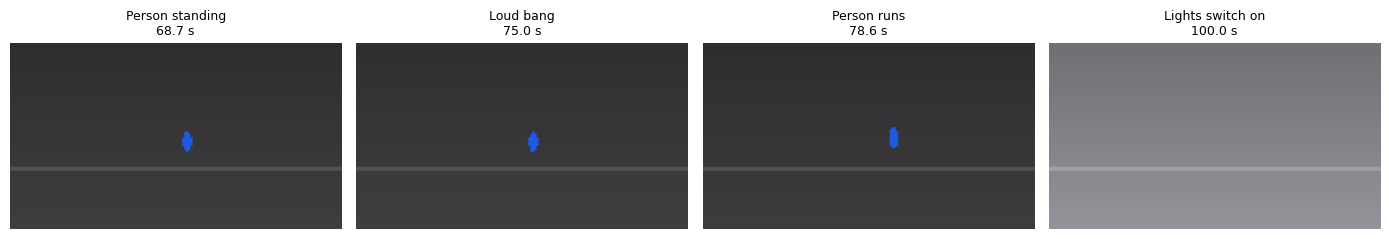

In [25]:
# TODO 1: person speed (px/s)
dx = cctv.person_x.diff(FPS)
dy = cctv.person_y.diff(FPS)
speed = np.hypot(dx, dy)

# TODO 2: standing / running time ranges (print the first and last time of each)
t = cctv.time_s.values
standing = (speed < 3).values
running  = (speed > 25).values
print(f"Standing: {t[standing][0]:.1f} s -> {t[standing][-1]:.1f} s")
print(f"Running : {t[running][0]:.1f} s -> {t[running][-1]:.1f} s")

# TODO 3: event frame indices
audio_event_idx    = int(np.argmax(cctv.audio_level_db.values > -20))
lighting_event_idx = int(np.argmax(cctv.mean_brightness.diff().values > 40))
stand_idx = int(np.argmax(standing))
run_idx   = int(np.argmax(running))
print(f"Audio event: {t[audio_event_idx]:.1f} s | Lighting event: {t[lighting_event_idx]:.1f} s")

# TODO 4: annotated motion-energy timeline
events = [(stand_idx, "Person standing"), (audio_event_idx, "Loud bang"),
          (run_idx, "Person runs"), (lighting_event_idx, "Lights switch on")]

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.8)
for i, label in events:
    ax.axvline(t[i], color="red", ls="--", lw=1)
    ax.text(t[i], ax.get_ylim()[1] * 0.95, f" {label}\n {t[i]:.1f}s", color="red",
            fontsize=8, va="top")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy")
ax.set_title("Lot B: four moments that matter in two minutes of video")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(14, 2.8))
for ax, (i, label) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[i])); ax.axis("off")
    ax.set_title(f"{label}\n{t[i]:.1f} s", fontsize=9)
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_ With one keyframe every 20 seconds, the bang at 75 s would be missed, and the runner could be missed too. The brightness change at 100 s might also be missed because it lasts only one frame. Fixed intervals do not account for important events. Instead, content-based keyframe selection (Slide 40) picks frames based on changes in motion, audio, or brightness, making it more likely to capture important moments.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

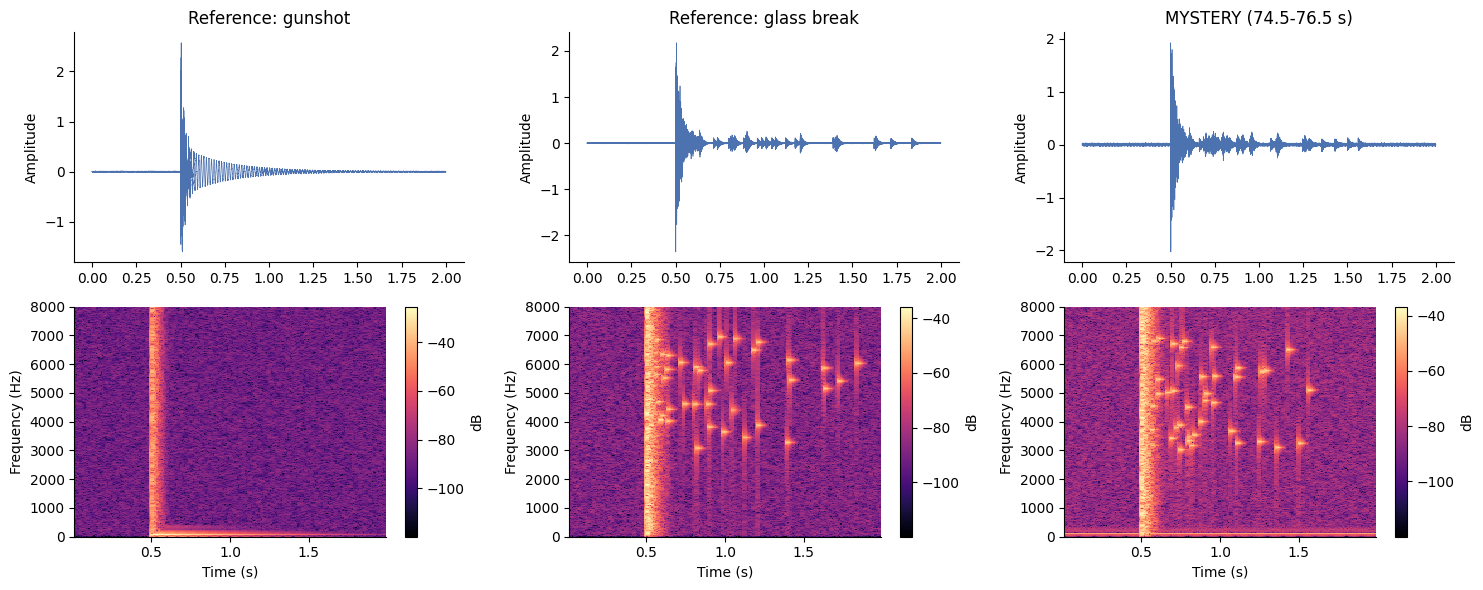

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
Verdict: the 75 s bang is a GLASS BREAK (HF energy 87% vs glass ref 99% and gunshot ref 0%).


In [26]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for j, (name, x) in enumerate(clips.items()):
    tt_wave = np.arange(x.size) / FS
    axes[0, j].plot(tt_wave, x, lw=0.5, color="#4C72B0")
    axes[0, j].set_title(name); axes[0, j].set_ylabel("Amplitude")

    f, tt, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    pcm = axes[1, j].pcolormesh(tt, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
    axes[1, j].set_ylim(0, 8000)
    axes[1, j].set_xlabel("Time (s)"); axes[1, j].set_ylabel("Frequency (Hz)")
    fig.colorbar(pcm, ax=axes[1, j], label="dB")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
IMPACT = 0.5
hf_fraction = {}
for name, x in clips.items():
    f, tt, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    win = (tt >= IMPACT + 0.2) & (tt <= IMPACT + 1.2)
    hf_fraction[name] = S[f > 3000][:, win].sum() / S[:, win].sum()

print({k: round(float(v), 3) for k, v in hf_fraction.items()})

# TODO 4: verdict
g, gl, m = (hf_fraction[k] for k in clips)
verdict = "GLASS BREAK" if abs(m - gl) < abs(m - g) else "GUNSHOT"
print(f"Verdict: the 75 s bang is a {verdict} "
      f"(HF energy {m:.0%} vs glass ref {gl:.0%} and gunshot ref {g:.0%}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ All three waveforms look similar, with a sudden spike followed by a decay, so they show when the impact happened but not what caused it. A spectrogram shows time, frequency, and intensity using colour. A gunshot appears as a short vertical stripe with a low-frequency boom, while breaking glass has scattered high-frequency sounds that last about a second. The mystery clip had these high-frequency sounds, with 87% of its post-impact energy above 3 kHz, unlike the gunshot. So, the sound was most likely breaking glass.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

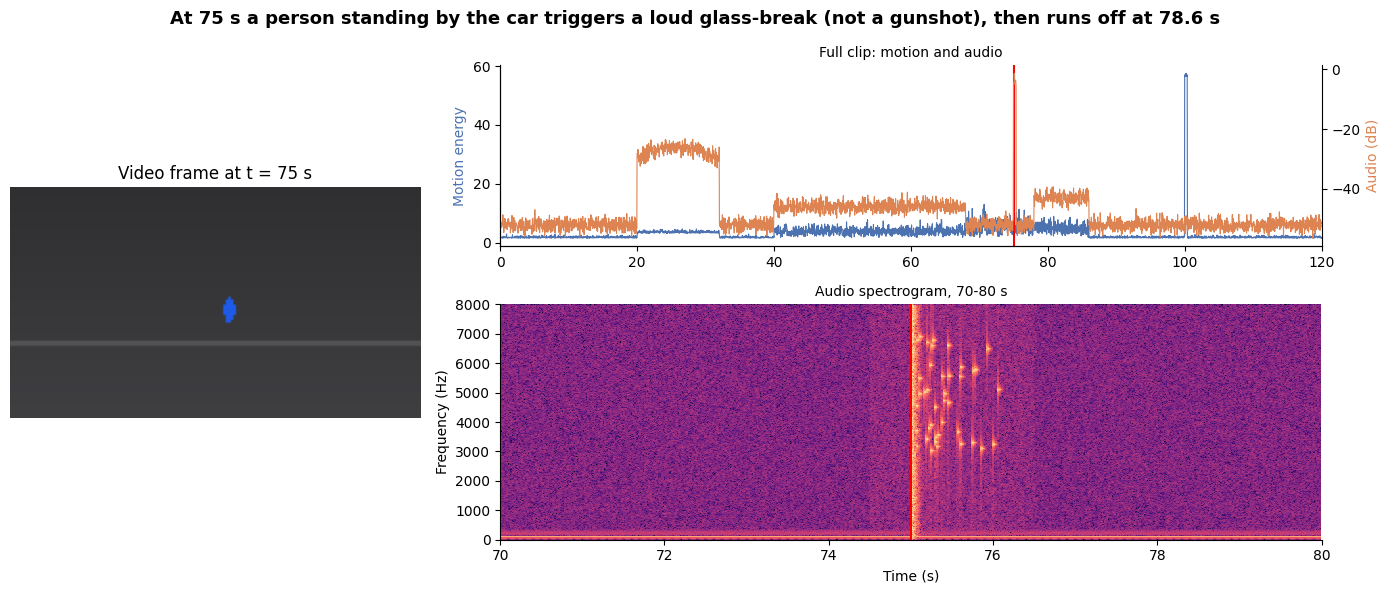

In [27]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[int(round(t_sel * FPS))]))
ax_frame.set_title(f"Video frame at t = {t_sel:.0f} s"); ax_frame.axis("off")

ax_tl = fig.add_subplot(gs[0, 1])
ax_tl.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.8, label="Motion energy")
ax_tl.set_ylabel("Motion energy", color="#4C72B0"); ax_tl.set_xlim(0, 120)
ax_au = ax_tl.twinx()
ax_au.plot(cctv.time_s, cctv.audio_level_db, color="#DD8452", lw=0.8, label="Audio level")
ax_au.set_ylabel("Audio (dB)", color="#DD8452")
ax_au.spines["right"].set_visible(True)
ax_tl.axvline(t_sel, color="red", lw=1.5)
ax_tl.set_title("Full clip: motion and audio", fontsize=10)

ax_sp = fig.add_subplot(gs[1, 1])
f, tt, S = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_sp.pcolormesh(tt + 70, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
ax_sp.set_ylim(0, 8000); ax_sp.set_xlim(70, 80)
ax_sp.axvline(t_sel, color="red", lw=1.5)
ax_sp.set_xlabel("Time (s)"); ax_sp.set_ylabel("Frequency (Hz)")
ax_sp.set_title("Audio spectrogram, 70-80 s", fontsize=10)

fig.suptitle("At 75 s a person standing by the car triggers a loud glass-break (not a gunshot), "
             "then runs off at 78.6 s", fontsize=13, fontweight="bold")

plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_ If the audio is delayed by 2 seconds, the bang would appear at 77 s instead of 75 s, causing the sound to mismatch with the video. This could lead to the wrong interpretation of what the person was doing when the glass broke. The error would be visible in the spectrogram, where the sound pattern would not match the red marker, and the timeline, where the audio spike would not align with the person's movement. This is why proper synchronization, as shown in Slide 59, is important.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ At 75 s, a loud impact in Lot B was identified as breaking glass rather than a gunshot, the person ran from 78.6 s to 86 s, and the lights switched on at 100 s. I would show the synchronized view first because it combines the timeline, video frames, and spectrogram, following the lecture's idea of overview first, detail on demand. The spectrogram supports the verdict because 87% of the mystery sound's post-impact energy is above 3 kHz, matching the glass reference. Downsampling to 640×360 at 10 fps would reduce storage from around 5,866 TB/day to 217 TB/day for 400 cameras. However, temporal resolution around important events must be preserved so fast movements are not missed, and audio should remain at 16 kHz to retain the frequencies needed for sound classification.